In [16]:
import logging

import numpy as np
import optimistix as optx

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models, IdealGas
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [17]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1.0  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [18]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

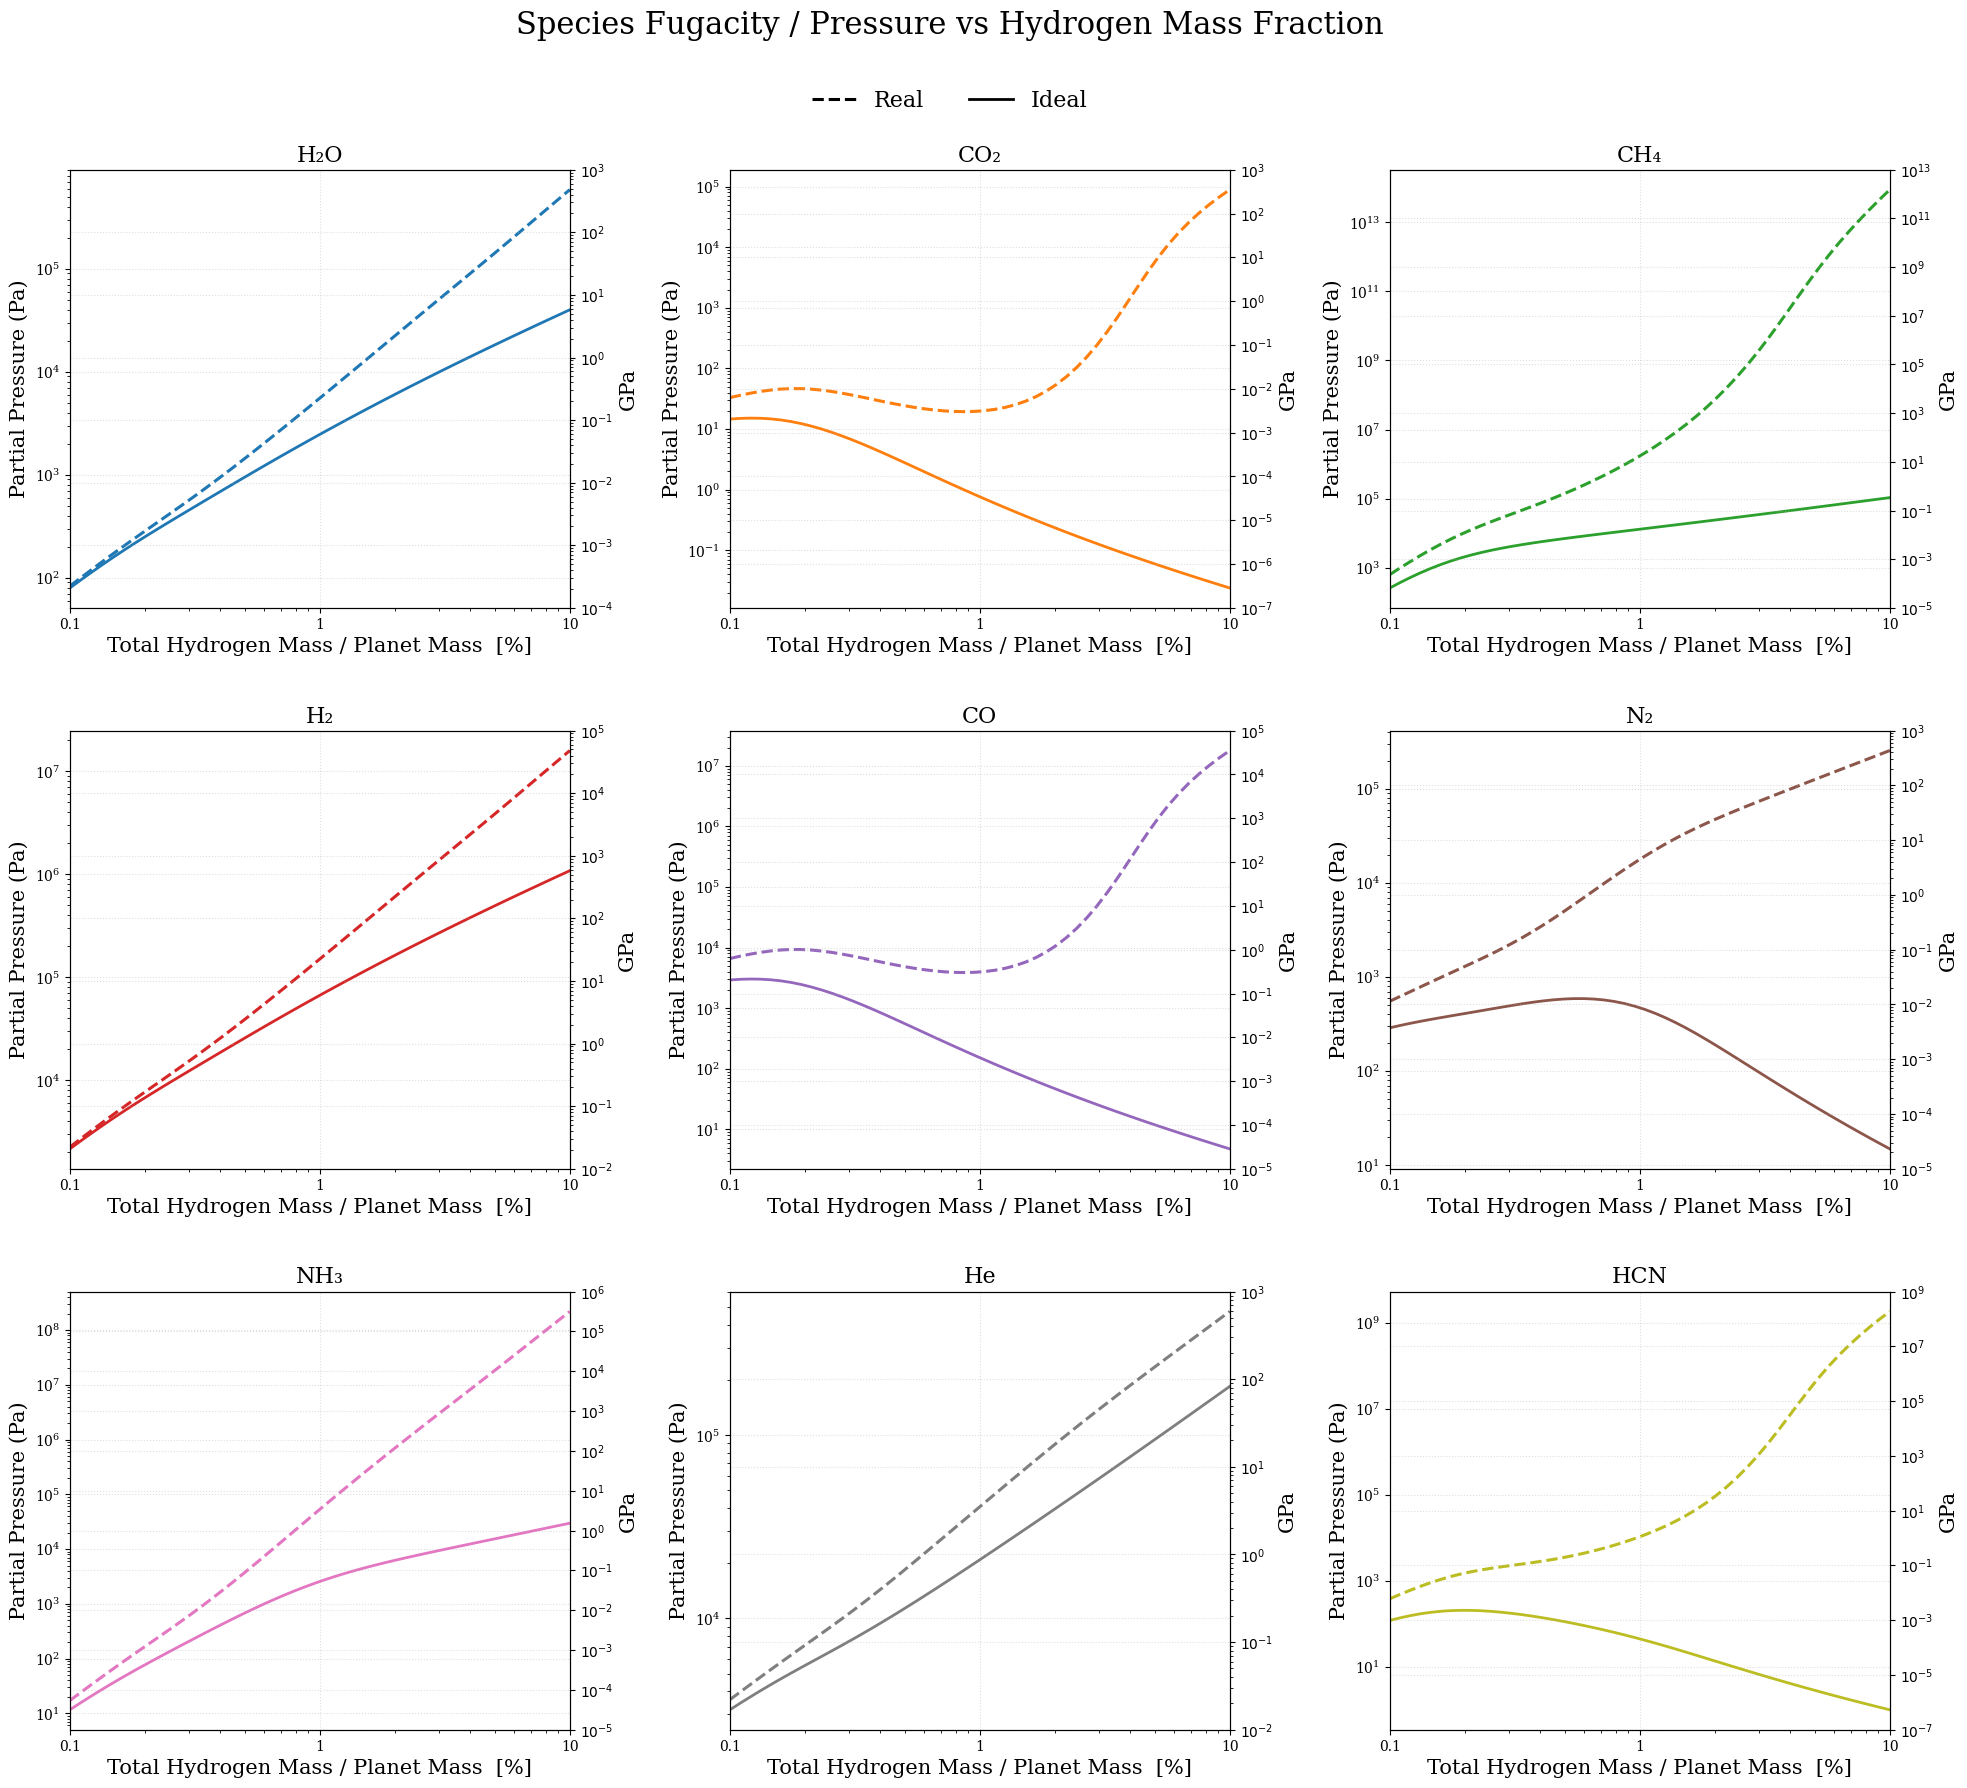

In [24]:
import numpy as np
import pandas as pd

import matplotlib.lines as mlines

real_handle  = mlines.Line2D([], [], color="black", lw=2.2, linestyle="--",  label="Real")
ideal_handle = mlines.Line2D([], [], color="black", lw=2.0, label="Ideal")


# ---------------------------------------------------------
# STYLE
# ---------------------------------------------------------
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 16
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

set_style()

# ---------------------------------------------------------
# INPUT FILES
# ---------------------------------------------------------
real_file  = "THEREALEST.xlsx"
ideal_file = "IDEALEST.xlsx"

species_real_sheets  = ["H2O_g","CO2_g","CH4_g","H2_g","CO_g","N2_g","H3N_g", 'He_g', 'CHN_g']
species_ideal_sheets = ["H2O_g","CO2_g","CH4_g","H2_g","CO_g","N2_g","H3N_g", 'He_g', 'CHN_g']
species_labels       = ["H₂O","CO₂","CH₄","H₂","CO","N₂","NH₃", 'He', 'HCN']

# ---------------------------------------------------------
# READ FILES
# ---------------------------------------------------------
read_real  = {s: pd.read_excel(real_file,  sheet_name=s) for s in species_real_sheets}
read_ideal = {s: pd.read_excel(ideal_file, sheet_name=s) for s in species_ideal_sheets}

planet_real  = pd.read_excel(real_file, sheet_name='element_H')
planet_ideal = pd.read_excel(real_file, sheet_name='element_H')

H2_frac_real  = (planet_real["total_mass"]  / planet_mass) * 100
H2_frac_ideal = (planet_ideal["total_mass"] / planet_mass) * 100

xticks = [0.1, 1, 10]

# ---------------------------------------------------------
# PARTIAL PRESSURES
# ---------------------------------------------------------
def partial_pressure_real(df):
    P_pa  = df["fugacity"]
    P_gpa = P_pa * 1e-4
    return P_pa, P_gpa

def partial_pressure_ideal(df):
    P_pa  = df["pressure"]
    P_gpa = P_pa * 1e-4
    return P_pa, P_gpa

# ---------------------------------------------------------
# PLOTTING
# ---------------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(20, 20))  # <-- larger figure
axes = axes.flatten()

colors = plt.get_cmap("tab10")(np.linspace(0, 1, 10))

for i, label in enumerate(species_labels):

    ax = axes[i]
    color = colors[i]

    dfR = read_real[species_real_sheets[i]]
    dfI = read_ideal[species_ideal_sheets[i]]

    P_real_pa,  P_real_gpa  = partial_pressure_real(dfR)
    P_ideal_pa, P_ideal_gpa = partial_pressure_ideal(dfI)

    # ---- Main axis (Pa) ----
    ax.plot(H2_frac_real,  P_real_pa,  color=color, ls="--", lw=2.2, label="Real")
    ax.plot(H2_frac_ideal, P_ideal_pa, color=color, lw=2.0, label="Ideal")

    ax.set_xscale("log")
    ax.set_xticks(xticks)
    ax.set_xticklabels(["0.1", "1", "10"])

    ax.set_yscale("log")
    ax.set_title(label)
    ax.set_ylabel("Partial Pressure (Pa)")

    # Add X-axis to every subplot
    ax.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")

    # ---- Twin axis (GPa) ----
    # ---- Twin axis (GPa) ----
    ax2 = ax.twinx()
    ax2.set_yscale("log")
    ax2.set_ylabel("GPa")
    
    # Make right axis match left axis tick positions,
    # but with exponent shifted by -4
    yticks_pa = ax.get_yticks()              # e.g. [1e2, 1e3, 1e4]
    yticks_gpa = yticks_pa * 1e-4            # shift by 10^-4
    
    ax2.set_yticks(yticks_gpa)
    
    # Format right-axis tick labels as powers of 10
    ax2.set_yticklabels([f"$10^{{{int(np.log10(t))}}}$" for t in yticks_gpa])


    ax.set_xlim(0.1, 10)

# ---------------------------------------------------------
# Legend + titles
# ---------------------------------------------------------
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles=[real_handle, ideal_handle],
           loc="upper center", ncol=2, frameon=False, fontsize = 16,
           bbox_to_anchor=(0.5, 0.91))


fig.subplots_adjust(left=0.06, right=0.97, top=0.86, bottom=0.08,
                    wspace=0.32, hspace=0.28)

plt.suptitle("Species Fugacity / Pressure vs Hydrogen Mass Fraction",
             fontsize=22, y=0.94)

plt.savefig("species_partial_pressures_real_ideal_compact.png",
            dpi=300, bbox_inches="tight")
plt.show()

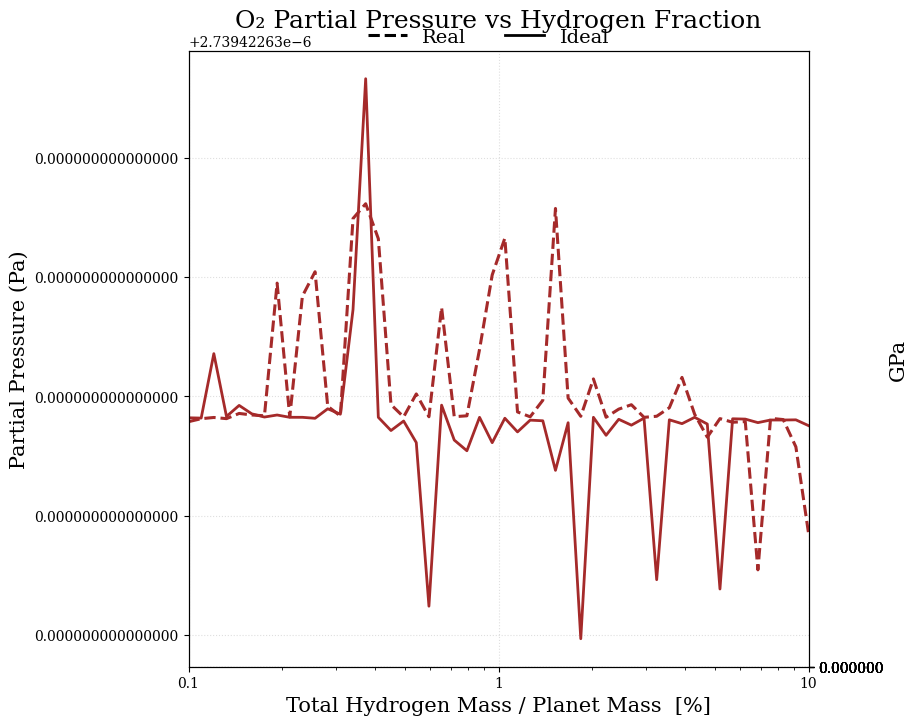

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

# Legend handles
real_handle  = mlines.Line2D([], [], color="black", lw=2.2, linestyle="--", label="Real")
ideal_handle = mlines.Line2D([], [], color="black", lw=2.0, label="Ideal")

# ---------------------------------------------------------
# STYLE
# ---------------------------------------------------------
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 18
    plt.rcParams["legend.fontsize"] = 14
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

set_style()

# ---------------------------------------------------------
# INPUT FILES
# ---------------------------------------------------------
real_file  = "THEREALEST.xlsx"
ideal_file = "IDEALEST.xlsx"

species_real_sheet  = "O2_g"
species_ideal_sheet = "O2_g"
species_label       = "O₂"

# ---------------------------------------------------------
# READ FILES
# ---------------------------------------------------------
dfR = pd.read_excel(real_file,  sheet_name=species_real_sheet)
dfI = pd.read_excel(ideal_file, sheet_name=species_ideal_sheet)

planet_real  = pd.read_excel(real_file, sheet_name="element_H")
planet_ideal = pd.read_excel(real_file, sheet_name="element_H")

H2_frac_real  = (planet_real["total_mass"]  / planet_mass) * 100
H2_frac_ideal = (planet_ideal["total_mass"] / planet_mass) * 100

xticks = [0.1, 1, 10]

# ---------------------------------------------------------
# PARTIAL PRESSURES
# ---------------------------------------------------------
def partial_pressure_real(df):
    P_pa = df["fugacity"]
    P_gpa = P_pa * 1e-4
    return P_pa, P_gpa

def partial_pressure_ideal(df):
    P_pa = df["pressure"]
    P_gpa = P_pa * 1e-4
    return P_pa, P_gpa

P_real_pa,  P_real_gpa  = partial_pressure_real(dfR)
P_ideal_pa, P_ideal_gpa = partial_pressure_ideal(dfI)

# ---------------------------------------------------------
# PLOTTING
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

color = "brown"

# ---- Main axis (Pa) ----
ax.plot(H2_frac_real,  P_real_pa,  color=color, ls="--", lw=2.2, label="Real")
ax.plot(H2_frac_ideal, P_ideal_pa, color=color, lw=2.0, label="Ideal")

ax.set_xscale("log")
ax.set_xticks(xticks)
ax.set_xticklabels(["0.1", "1", "10"])

ax.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")
ax.set_ylabel("Partial Pressure (Pa)")
ax.set_title("O₂ Partial Pressure vs Hydrogen Fraction")

# Disable scientific notation
ax.ticklabel_format(style="plain", axis="y")

# ---------------------------------------------------------
# Right axis (GPa = Pa × 10⁻⁴), linear scale
# ---------------------------------------------------------
ax2 = ax.twinx()
ax2.set_ylabel("GPa")
ax2.ticklabel_format(style="plain", axis="y")

# Match tick positions
yticks_pa = ax.get_yticks()
yticks_gpa = yticks_pa * 1e-4

ax2.set_yticks(yticks_gpa)
ax2.set_yticklabels([f"{t:.6f}" for t in yticks_gpa])

ax.set_xlim(0.1, 10)

# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------
fig.legend(handles=[real_handle, ideal_handle],
           loc="upper center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 0.93))

fig.subplots_adjust(top=0.88)

plt.savefig("O2_partial_pressure_plot.png", dpi=300, bbox_inches="tight")
plt.show()


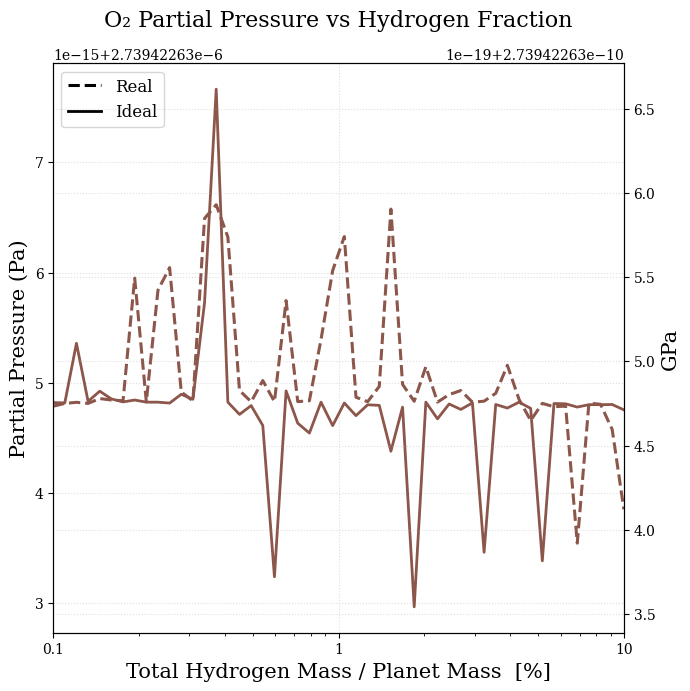

In [33]:
import numpy as np
import pandas as pd
import matplotlib.lines as mlines

# ---------------------------------------------
# STYLE
# ---------------------------------------------
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 16
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

set_style()

# ---------------------------------------------
# INPUT FILES
# ---------------------------------------------
real_file  = "THEREALEST.xlsx"
ideal_file = "IDEALEST.xlsx"

# O₂ sheets
real_sheet  = "O2_g"
ideal_sheet = "O2_g"
label       = "O₂"

# ---------------------------------------------
# READ DATA
# ---------------------------------------------
dfR = pd.read_excel(real_file,  sheet_name=real_sheet)
dfI = pd.read_excel(ideal_file, sheet_name=ideal_sheet)

planet_real = pd.read_excel(real_file, sheet_name="element_H")
planet_ideal = pd.read_excel(real_file, sheet_name="element_H")

H2_frac_real  = (planet_real["total_mass"]  / planet_mass) * 100
H2_frac_ideal = (planet_ideal["total_mass"] / planet_mass) * 100

# ---------------------------------------------
# PARTIAL PRESSURES
# ---------------------------------------------
def partial_pressure_real(df):
    P_pa  = df["fugacity"]
    P_gpa = P_pa * 1e-4
    return P_pa, P_gpa

def partial_pressure_ideal(df):
    P_pa  = df["pressure"]
    P_gpa = P_pa * 1e-4
    return P_pa, P_gpa

P_real_pa,  P_real_gpa  = partial_pressure_real(dfR)
P_ideal_pa, P_ideal_gpa = partial_pressure_ideal(dfI)

# ---------------------------------------------
# PLOT (single reference figure)
# ---------------------------------------------
fig, ax = plt.subplots(figsize=(7, 7))

# main (Pa)
ax.plot(H2_frac_real,  P_real_pa,  color="tab:brown", ls="--", lw=2.2)
ax.plot(H2_frac_ideal, P_ideal_pa, color="tab:brown", lw=2.0)

ax.set_xscale("log")
ax.set_xticks([0.1, 1, 10])
ax.set_xticklabels(["0.1", "1", "10"])
ax.set_xlim(0.1, 10)

ax.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")
ax.set_ylabel("Partial Pressure (Pa)")
ax.set_title(f"{label} Partial Pressure vs Hydrogen Fraction", y = 1.05)

# twin axis (GPa)
ax2 = ax.twinx()
ax2.plot(H2_frac_real, P_real_gpa, color="black", alpha=0.0)
ax2.set_ylabel("GPa")

# ---------------------------------------------
# Legend (black handles)
# ---------------------------------------------
real_handle  = mlines.Line2D([], [], color="black", lw=2.2, linestyle="--", label="Real")
ideal_handle = mlines.Line2D([], [], color="black", lw=2.0, label="Ideal")

ax.legend(handles=[real_handle, ideal_handle], loc="upper left")

plt.tight_layout()
plt.show()